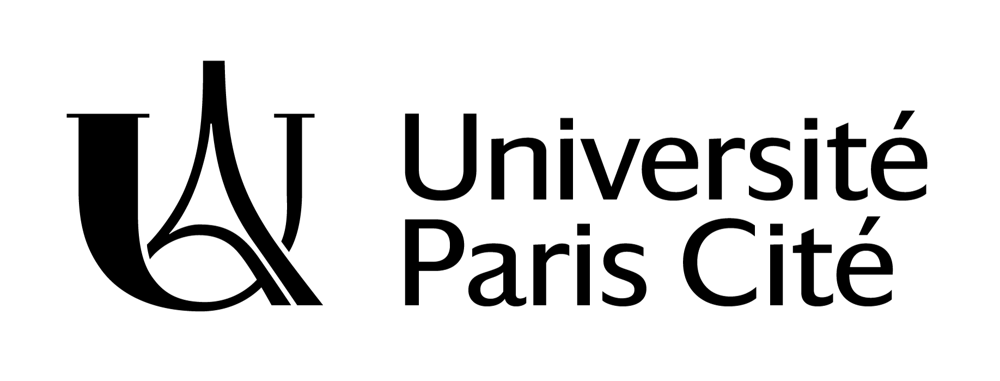



# M2 VMI - TP GenAI: Catch them all (and more)

You can choose to do this lab on either a Google Colab instance, or locally. If you do it on a Colab instance, make sure to activate the GPU.

Images: © Nintendo/Game Freak.

Exercises after d2l.ai

## 1) Loading the data
Let's get all of the data required for this lab.


## Experimental protocol
Three configurations per model, 20 epochs each. Same folder-level split, batch size and seed. Only one parameter changes relative to each baseline. Best configuration is selected by final-epoch FID within each model; KID and visual quality provide complementary evidence. Architecture follows the original lab. Enable Kaggle GPU and Internet. Each completed experiment is saved independently.

In [1]:
from pathlib import Path
import urllib.request
import zipfile

if not Path('pokemon/25').is_dir():
    url = 'https://d2l-data.s3-accelerate.amazonaws.com/pokemon.zip'
    if not Path('pokemon.zip').exists():
        urllib.request.urlretrieve(url, 'pokemon.zip')
    with zipfile.ZipFile('pokemon.zip') as archive:
        archive.extractall('.')
print('Dataset ready')


Dataset ready


As you might have guessed, we will look at pokemons (the data is from https://pokemondb.net/sprites)

For some of them, you even have several sprites that form an animation!

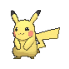

In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from pathlib import PurePath

# List of image filenames
filenames = [str(PurePath('pokemon', '25', f'25-{i}.png')) for i in range(33)]

fig, ax = plt.subplots(figsize=(0.64, 0.64), dpi=100)
img = mpimg.imread(filenames[0])
im = ax.imshow(img)
ax.axis('off')

def update(frame):
    img = mpimg.imread(filenames[frame])
    im.set_array(img)
    return [im]

ani = FuncAnimation(fig, update, frames=len(filenames), interval=60, blit=True)

# Display the animation as an HTML5 video in Colab
HTML(ani.to_jshtml())

Load the dataset, and vizualize a few samples:

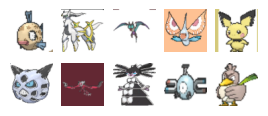

In [3]:
import warnings
import torch
import torchvision
from torch import nn

pokemon = torchvision.datasets.ImageFolder('pokemon')
batch_size = 128
transformer = torchvision.transforms.Compose([
    torchvision.transforms.Resize((64, 64)),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(0.5, 0.5)
])
pokemon.transform = transformer
data_iter = torch.utils.data.DataLoader(
    pokemon, batch_size=batch_size,
    shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())

warnings.filterwarnings('ignore')
num_rows = 2
num_cols = 5
fig, axes = plt.subplots(num_rows, num_cols, figsize=(0.64*num_cols, 0.64*num_rows), dpi=100)
for X, y in data_iter:
    imgs = X[:num_rows * num_cols,:,:,:].permute(0, 2, 3, 1)/2+0.5
    for img_index, img in enumerate(imgs):
      axes[img_index//num_cols, img_index%num_cols].imshow(img)
      axes[img_index//num_cols, img_index%num_cols].axis('off')
    break

In [4]:
# Reproducible split by Pokémon folder (rather than individual sprite).
import random, numpy as np, pandas as pd
from torch.utils.data import DataLoader, Subset
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
classes = np.unique(pokemon.targets)
rng = np.random.default_rng(SEED)
classes = rng.permutation(classes)
n_val = max(1, int(0.2 * len(classes)))
val_classes = set(classes[:n_val])
train_idx = [i for i,y in enumerate(pokemon.targets) if y not in val_classes]
val_idx = [i for i,y in enumerate(pokemon.targets) if y in val_classes]
assert train_idx and val_idx
# Both models use the same split.
data_iter = DataLoader(Subset(pokemon, train_idx), batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
val_iter = DataLoader(Subset(pokemon, val_idx), batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
print(f'Train: {len(train_idx)} | Held-out: {len(val_idx)}')


Train: 32469 | Held-out: 8128


In [5]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

def try_gpu():
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class Timer:
    def __init__(self):
        self.start_time = None
        self.total_time = 0
    def start(self):
        self.start_time = time.time()
    def stop(self):
        if self.start_time is None:
            return 0
        self.total_time += time.time() - self.start_time
        self.start_time = None
        return self.total_time

class Accumulator:
    """Accumulate sums over n variables."""
    def __init__(self, n):
        self.data = [0.0] * n
    def add(self, *args):
        self.data = [a + float(b) for a, b in zip(self.data, args)]
    def reset(self):
        self.data = [0.0] * len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

In [6]:
# Image quality metrics (Kaggle Internet needed for pretrained Inception weights).
%pip -q install torchmetrics torch-fidelity


Note: you may need to restart the kernel to use updated packages.


In [7]:
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.functional.image import structural_similarity_index_measure
import time
from pathlib import Path
OUT = Path('pokemon_results'); OUT.mkdir(exist_ok=True)
device = try_gpu()
# Fixed held-out reference and fixed noise for fair comparisons across epochs.
EVAL_N = min(512, len(val_idx))
assert EVAL_N >= 2
EVAL_EVERY = 5
ref_loader = DataLoader(Subset(pokemon, np.random.default_rng(SEED).choice(val_idx, EVAL_N, replace=False).tolist()), batch_size=32, shuffle=False)
ref_images = torch.cat([x for x,_ in ref_loader]).mul(0.5).add(0.5)
fid_metric = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(device)
kid_metric = KernelInceptionDistance(feature=2048, normalize=True, subset_size=min(50,EVAL_N), subsets=10, reset_real_features=False).to(device)
for x in ref_images.split(32):
    fid_metric.update(x.to(device), real=True)
    kid_metric.update(x.to(device), real=True)
@torch.no_grad()
def generation_scores(model, kind, z):
    model.eval()
    for batch in z.split(32):
        x = model.decode(batch) if kind == 'VAE' else model(batch).mul(0.5).add(0.5)
        x = x.clamp(0,1)
        fid_metric.update(x, real=False); kid_metric.update(x, real=False)
    fid = fid_metric.compute().item(); mean, std = kid_metric.compute()
    fid_metric.reset(); kid_metric.reset()
    return fid, mean.item(), std.item()

def sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

def plot_history(df, groups, name):
    for columns in groups:
        fig, ax = plt.subplots(figsize=(7,4))
        for col in columns:
            if col in df:
                d = df.dropna(subset=[col]); ax.plot(d.epoch, d[col], 'o-', label=col)
        ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(OUT / (name+'_'+columns[0]+'.png'), dpi=150); plt.show(); plt.close(fig)


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 381MB/s]


## Configurations

In [8]:
EPOCHS = 20
VAE_CONFIGS = [dict(name='VAE1', latent_dim=128, lr=1e-3),
               dict(name='VAE2', latent_dim=64, lr=1e-3),
               dict(name='VAE3', latent_dim=128, lr=5e-4)]
GAN_CONFIGS = [dict(name='GAN1', latent_dim=100, lr_G=2e-4, lr_D=2e-4),
               dict(name='GAN2', latent_dim=100, lr_G=2e-4, lr_D=1e-4),
               dict(name='GAN3', latent_dim=100, lr_G=2e-4, lr_D=5e-5)]
from torchvision.utils import make_grid
import gc

def reset_seed():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

def loader():
    return DataLoader(Subset(pokemon, train_idx), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED), num_workers=2,
                      pin_memory=torch.cuda.is_available())

def grid_save(images, name, nrow=4):
    fig, ax = plt.subplots(figsize=(8, 8 if nrow==4 else 2.5))
    ax.imshow(make_grid(images.detach().cpu().clamp(0,1), nrow=nrow).permute(1,2,0))
    ax.set_title(name); ax.axis('off'); fig.tight_layout()
    fig.savefig(OUT/(name+'.png'), dpi=150); plt.show(); plt.close(fig)

display(pd.DataFrame(VAE_CONFIGS)); display(pd.DataFrame(GAN_CONFIGS))


,name,latent_dim,lr
0,VAE1,128,0.0010
1,VAE2,64,0.0010
2,VAE3,128,0.0005


,name,latent_dim,lr_G,lr_D
0,GAN1,100,0.0002,0.00020
1,GAN2,100,0.0002,0.00010
2,GAN3,100,0.0002,0.00005


## Part 1 - VAE
### 1.1 Defining the architecture
We will create a simple architecture for our auto-encoder.

In [9]:
# Define the VAE model
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=128):
        super(ConvVAE, self).__init__()
        self.latent_dim = latent_dim

        # Encoder: 3x64x64 input RGB images
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),  # 32x32x32
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),  # 64x16x16
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1),  # 128x8x8
            nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1),  # 256x4x4
            nn.ReLU(),
        )

        self.fc_mu = nn.Linear(256*4*4, latent_dim)
        self.fc_logvar = nn.Linear(256*4*4, latent_dim)

        # Decoder
        self.fc_decoder = nn.Linear(latent_dim, 256*4*4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1),  # 128x8x8
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  # 64x16x16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),  # 32x32x32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),  # 3x64x64
            nn.Sigmoid(),  # Output in [0,1]
        )

    def encode(self, x):
        h = self.encoder(x)
        h = h.view(h.size(0), -1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_decoder(z)
        h = h.view(h.size(0), 256, 4, 4)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar

### 1.2 Training and evaluation for each configuration

In [10]:
import torch.nn.functional as F

def vae_loss(recon, x, mu, logvar):
    mse = F.mse_loss(recon, x, reduction='sum')
    kl = -0.5 * torch.sum(1 + logvar - mu.square() - logvar.exp())
    return mse + kl, mse, kl

@torch.no_grad()
def evaluate_vae(model):
    model.eval(); sums = np.zeros(6); count = 0
    for X,_ in val_iter:
        X = X.to(device).mul(.5).add(.5)
        recon, mu, logvar = model(X)
        loss, rec, kl = vae_loss(recon,X,mu,logvar)
        # Deterministic reconstruction using posterior mean for image metrics.
        pred = model.decode(mu)
        mse = (pred-X).square().flatten(1).mean(1)
        psnr = -10*torch.log10(mse.clamp_min(1e-12))
        ssim = structural_similarity_index_measure(pred, X, data_range=1., reduction='none')
        sums += [loss.item(), rec.item(), kl.item(), mse.sum().item(), psnr.sum().item(), ssim.sum().item()]
        count += len(X)
    return dict(zip(['val_loss','val_recon','val_kl','mse','psnr','ssim'], sums/count))


def run_vae(cfg):
    reset_seed(); name=cfg['name']; run_loader=loader()
    vae = ConvVAE(latent_dim=cfg['latent_dim']).to(device)
    num_epochs = EPOCHS
    optimizer = torch.optim.Adam(vae.parameters(), lr=cfg['lr'])
    vae_z = torch.randn(EVAL_N, vae.latent_dim, device=device, generator=torch.Generator(device=device).manual_seed(SEED))
    vae_rows = []
    for epoch in range(1,num_epochs+1):
        vae.train(); sums = np.zeros(3); count=0; sync(); start=time.perf_counter()
        for X,_ in run_loader:
            X = X.to(device).mul(.5).add(.5)
            optimizer.zero_grad(); recon,mu,logvar = vae(X)
            loss,rec,kl = vae_loss(recon,X,mu,logvar)
            loss.backward(); optimizer.step()
            sums += [loss.item(),rec.item(),kl.item()]; count += len(X)
        sync(); elapsed=time.perf_counter()-start
        row = dict(epoch=epoch, **dict(zip(['train_loss','train_recon','train_kl'],sums/count)), train_seconds=elapsed, images_sec=count/elapsed)
        row.update(evaluate_vae(vae))
        if epoch % EVAL_EVERY == 0 or epoch == num_epochs:
            row.update(zip(['fid','kid','kid_std'],generation_scores(vae,'VAE',vae_z)))
        vae_rows.append(row); vae_history=pd.DataFrame(vae_rows)
        vae_history.to_csv(OUT/(name+'_history.csv'),index=False)
        print(row)
        torch.save(vae.state_dict(), OUT/(name+'_latest.pth'))
    plot_history(vae_history,[['train_loss','val_loss'],['train_recon','val_recon'],['train_kl','val_kl'],['mse'],['psnr'],['ssim'],['fid'],['kid'],['images_sec']], name)
    vae.eval()
    with torch.no_grad():
        grid_save(vae.decode(vae_z[:16]), name+'_generated')
        real=ref_images[:8].to(device)
        grid_save(torch.cat([real, vae.decode(vae.encode(real)[0])]), name+'_reconstruction', nrow=8)
        a=torch.linspace(0,1,8,device=device).view(-1,1)
        grid_save(vae.decode((1-a)*vae_z[0]+a*vae_z[1]), name+'_interpolation', nrow=8)
    return vae_history


Training {'name': 'VAE1', 'latent_dim': 128, 'lr': 0.001}
{'epoch': 1, 'train_loss': np.float64(712.430390454164), 'train_recon': np.float64(688.8093448269889), 'train_kl': np.float64(23.621047345897818), 'train_seconds': 13.977001868999878, 'images_sec': 2323.030382646956, 'val_loss': np.float64(567.518985778328), 'val_recon': np.float64(536.1491848202202), 'val_kl': np.float64(31.369801949328323), 'mse': np.float64(0.04157717986487028), 'psnr': np.float64(14.076215158297321), 'ssim': np.float64(0.33439169131864716)}
{'epoch': 2, 'train_loss': np.float64(491.5879989615094), 'train_recon': np.float64(450.3583580444039), 'train_kl': np.float64(41.22964195475396), 'train_seconds': 13.351724116000014, 'images_sec': 2431.8207684572235, 'val_loss': np.float64(481.3451213686485), 'val_recon': np.float64(432.32103555033524), 'val_kl': np.float64(49.02408650916392), 'mse': np.float64(0.034135975632963216), 'psnr': np.float64(14.899231317475087), 'ssim': np.float64(0.3935411976078364)}
{'epoch'

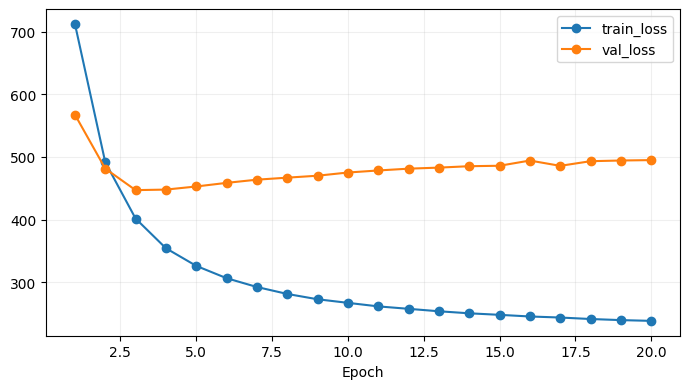

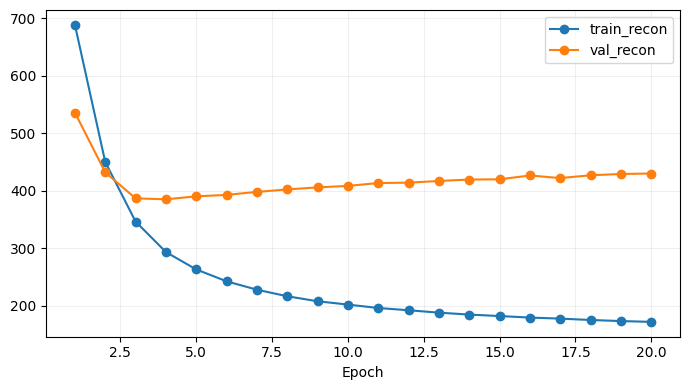

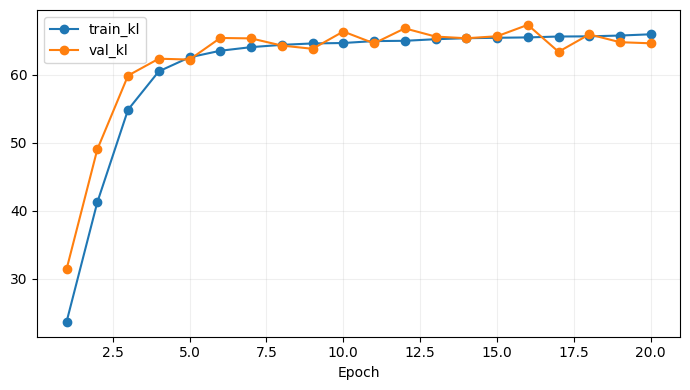

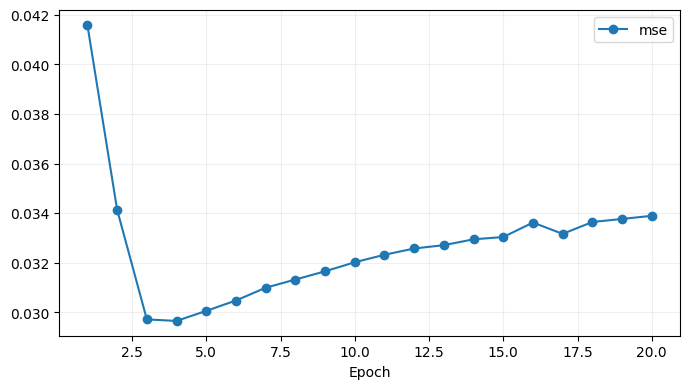

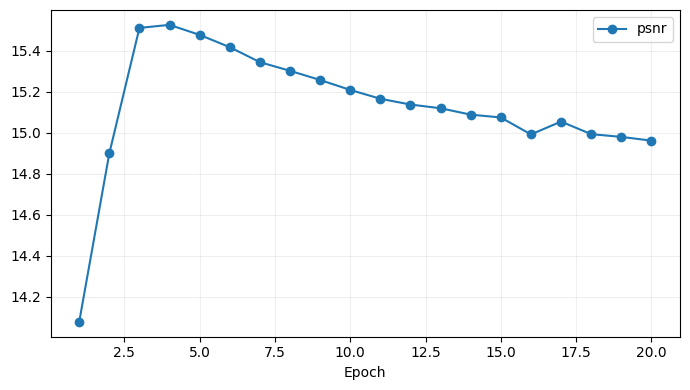

...

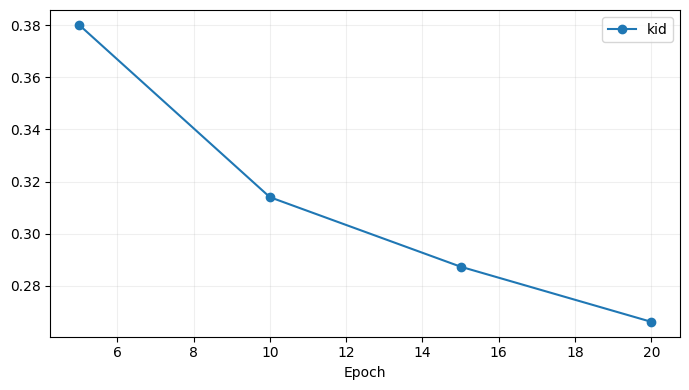

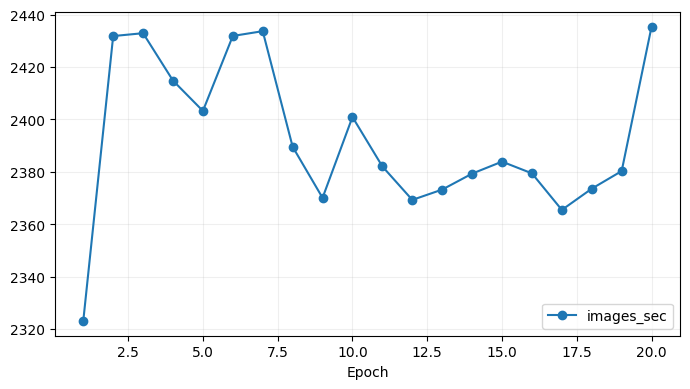

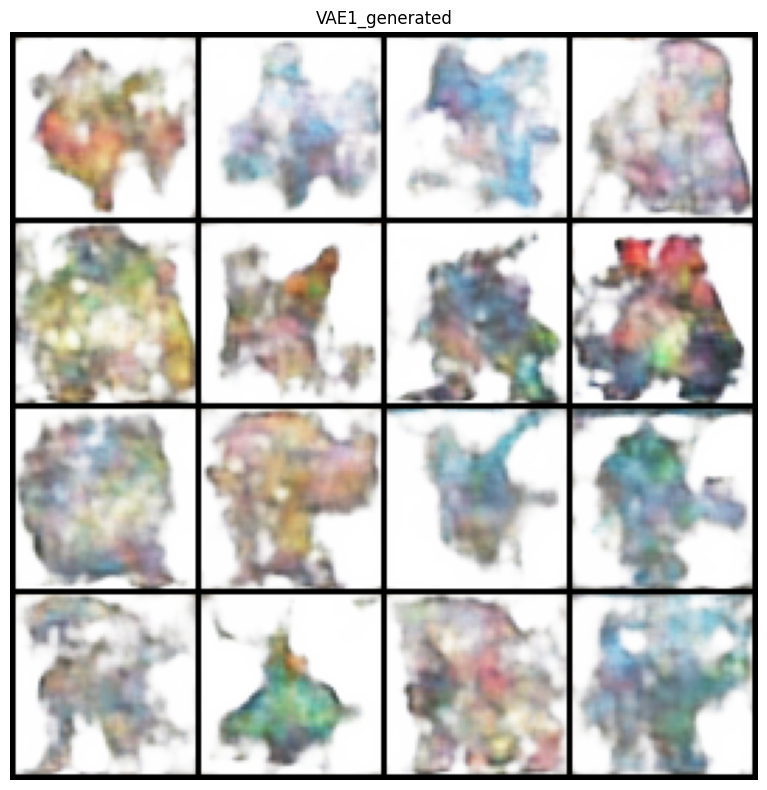

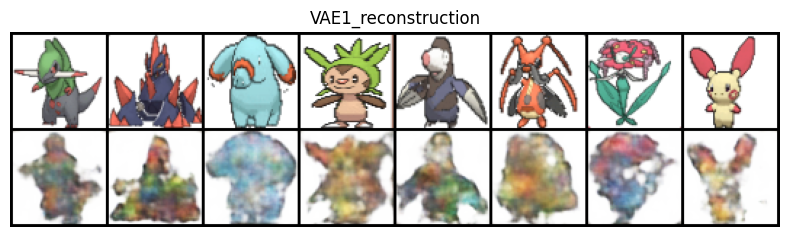

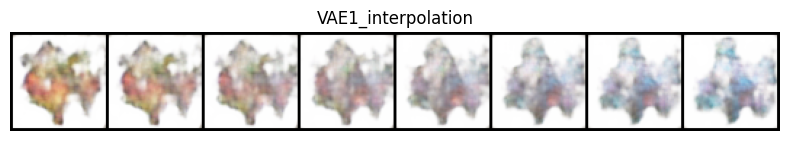

Training {'name': 'VAE2', 'latent_dim': 64, 'lr': 0.001}
{'epoch': 1, 'train_loss': np.float64(711.2124652793818), 'train_recon': np.float64(688.8372921575195), 'train_kl': np.float64(22.375173612581417), 'train_seconds': 13.696457243000168, 'images_sec': 2370.6130296280735, 'val_loss': np.float64(563.340741014856), 'val_recon': np.float64(533.0117211529589), 'val_kl': np.float64(30.329019321231392), 'mse': np.float64(0.04229020825990542), 'psnr': np.float64(14.011738859762357), 'ssim': np.float64(0.3258345422782297)}
{'epoch': 2, 'train_loss': np.float64(490.92472892412763), 'train_recon': np.float64(452.28425563133294), 'train_kl': np.float64(38.64047248824119), 'train_seconds': 13.67469161300005, 'images_sec': 2374.386269093839, 'val_loss': np.float64(471.0344497800812), 'val_recon': np.float64(422.7674603800135), 'val_kl': np.float64(48.26699111217589), 'mse': np.float64(0.03325980378124188), 'psnr': np.float64(15.007539779182494), 'ssim': np.float64(0.3887030238241661)}
{'epoch': 

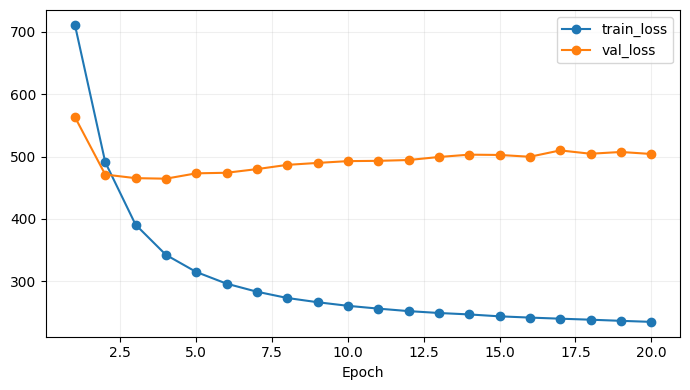

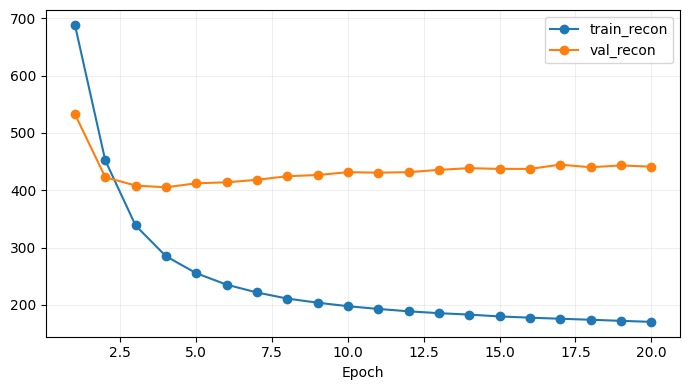

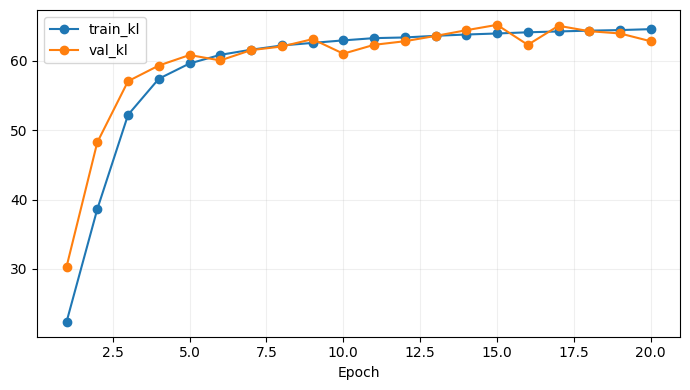

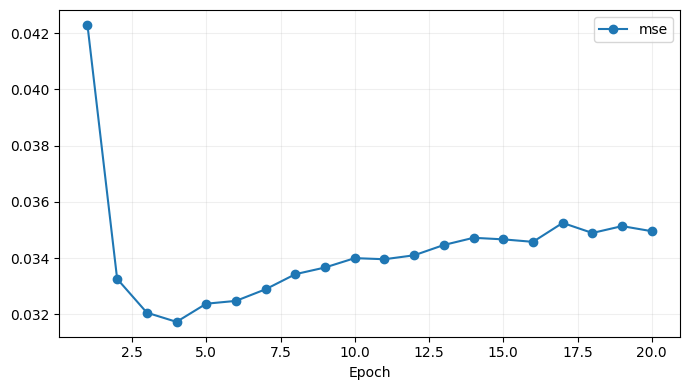

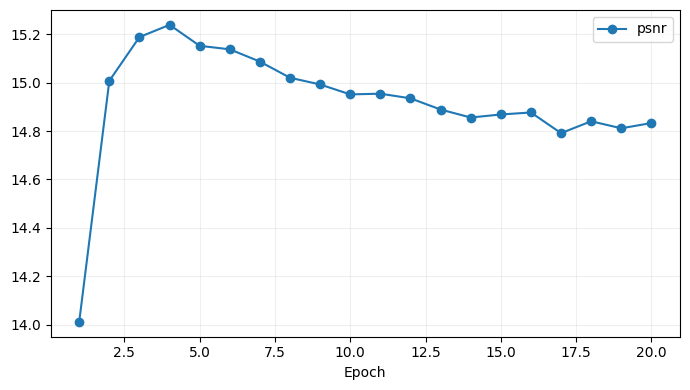

...

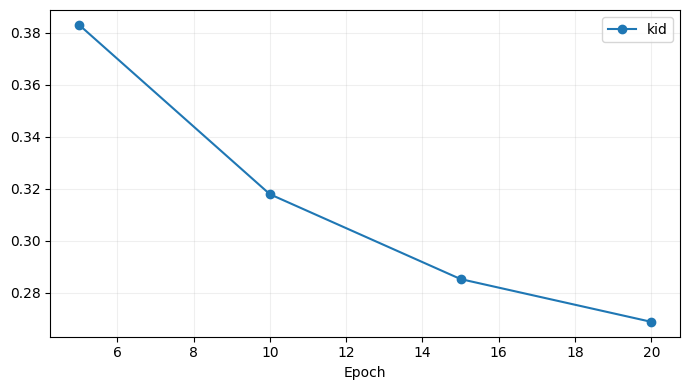

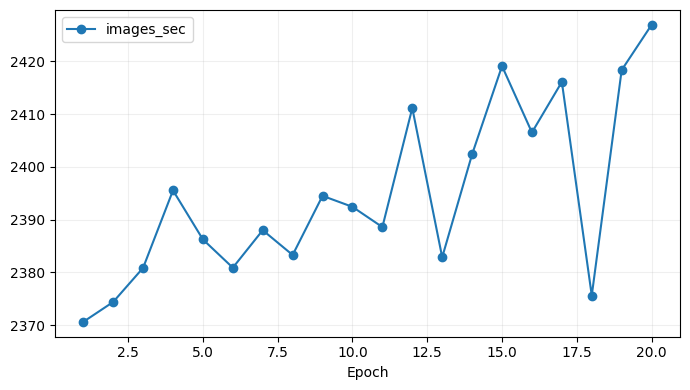

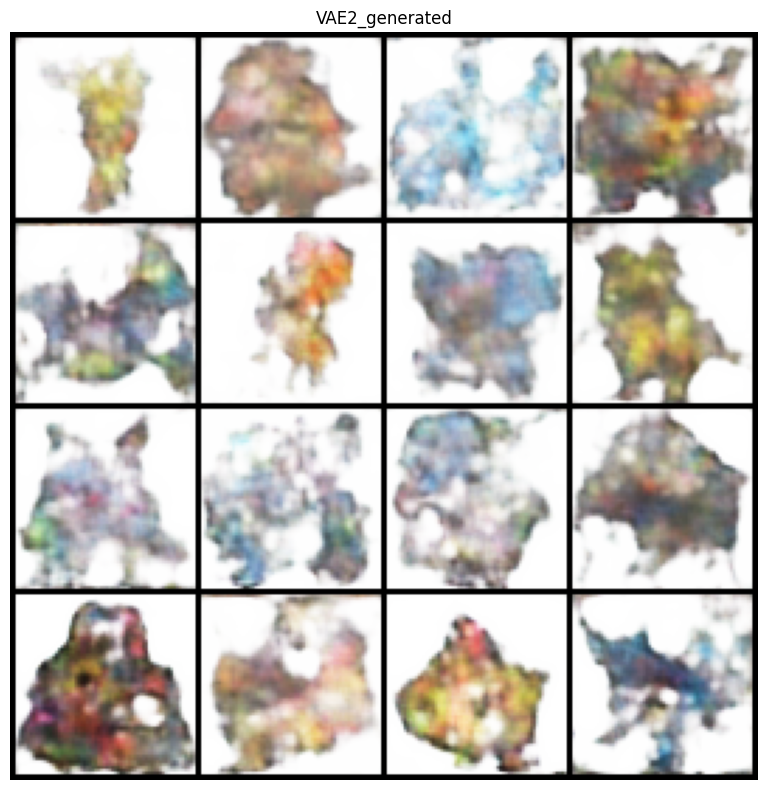

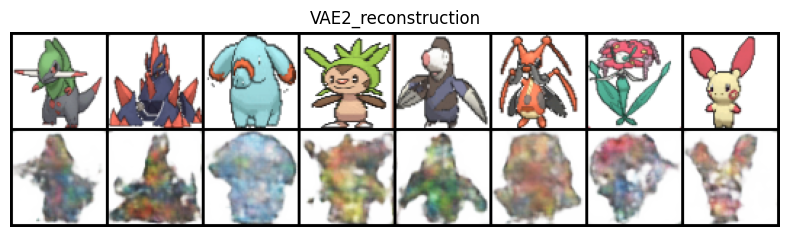

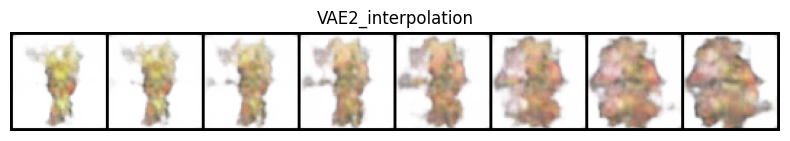

Training {'name': 'VAE3', 'latent_dim': 128, 'lr': 0.0005}
{'epoch': 1, 'train_loss': np.float64(718.3641374753611), 'train_recon': np.float64(692.5924536914057), 'train_kl': np.float64(25.771684940912294), 'train_seconds': 13.573090978999971, 'images_sec': 2392.159608318799, 'val_loss': np.float64(571.37538711668), 'val_recon': np.float64(533.5983324426365), 'val_kl': np.float64(37.777055304820145), 'mse': np.float64(0.0419955860354065), 'psnr': np.float64(14.02183910429947), 'ssim': np.float64(0.32644268072496246)}
{'epoch': 2, 'train_loss': np.float64(504.3078571098586), 'train_recon': np.float64(460.0827972450645), 'train_kl': np.float64(44.22506064679001), 'train_seconds': 13.493203895000079, 'images_sec': 2406.3224903932137, 'val_loss': np.float64(484.2199329766702), 'val_recon': np.float64(433.4275063341997), 'val_kl': np.float64(50.79242493036225), 'mse': np.float64(0.03423715799342929), 'psnr': np.float64(14.894829937792199), 'ssim': np.float64(0.3938464911903922)}
{'epoch': 3

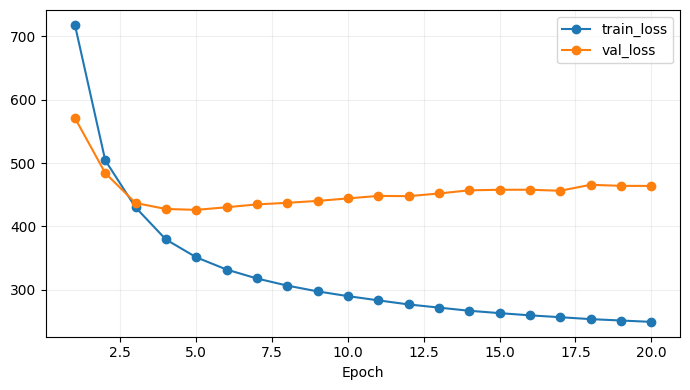

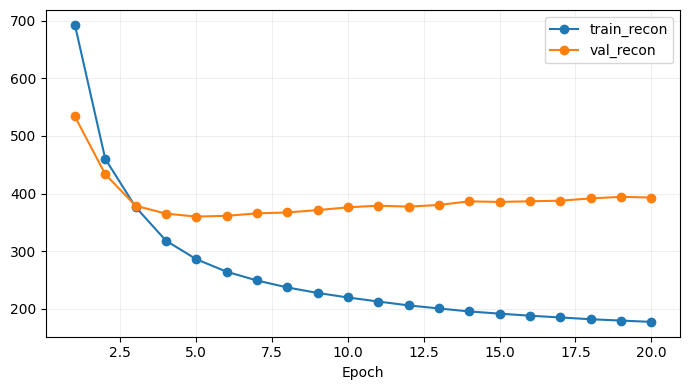

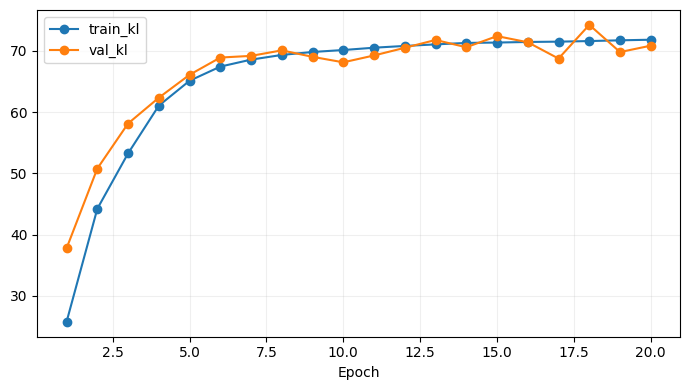

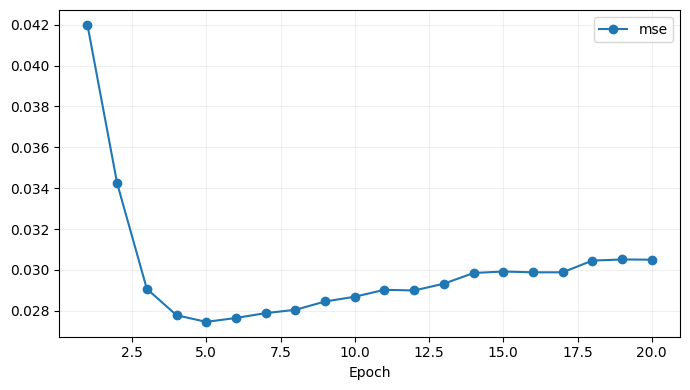

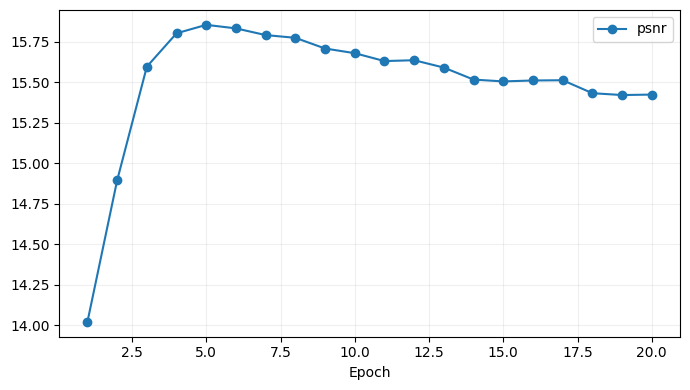

...

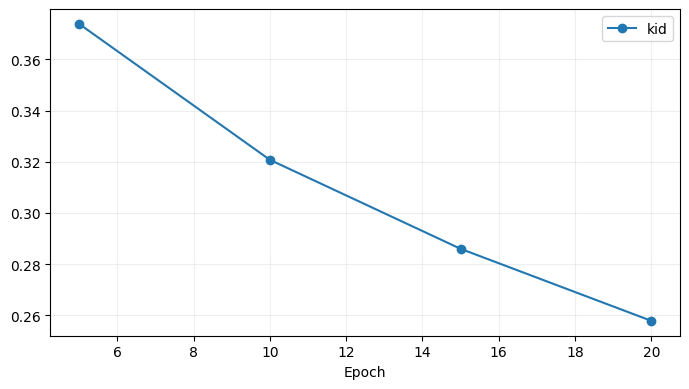

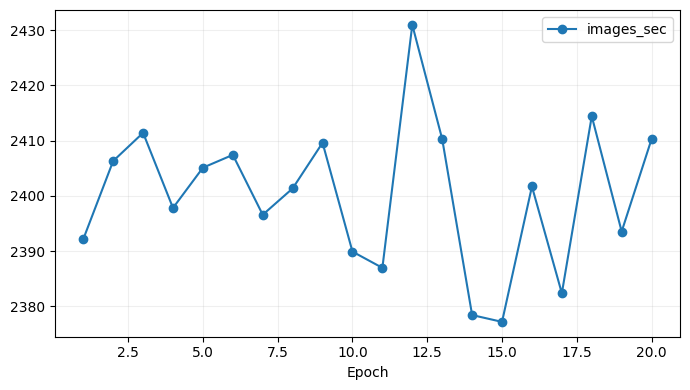

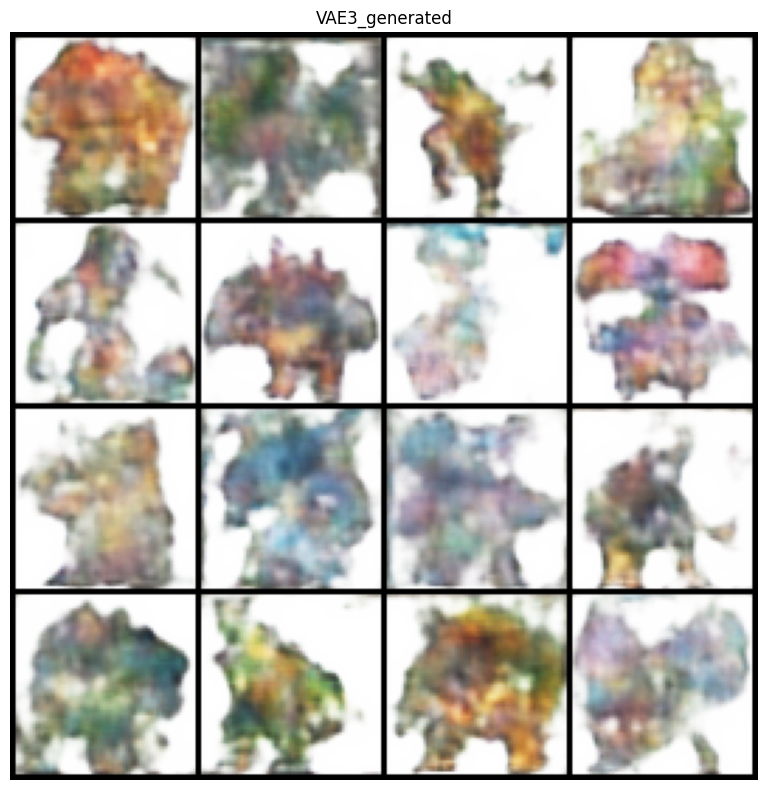

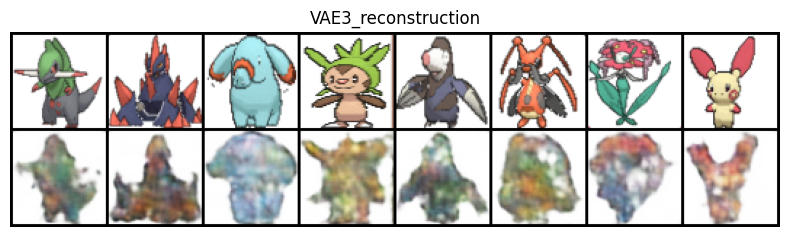

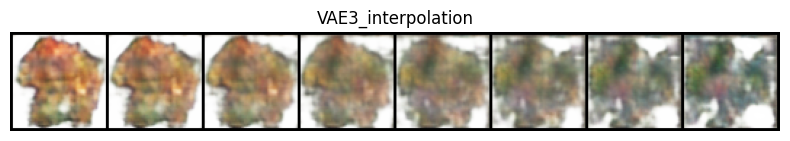

In [11]:
vae_histories={}
for cfg in VAE_CONFIGS:
    print('Training', cfg)
    vae_histories[cfg['name']]=run_vae(cfg)
    gc.collect(); torch.cuda.empty_cache()


## Part 2: GAN
### 2.1 GAN model - generator
Let's create a very simple generator, doing a series of 4 convolutions, and one transposed convolution.

In [12]:
class G_block(nn.Module):
    def __init__(self, out_channels, in_channels=3, kernel_size=4, strides=2,
                 padding=1, **kwargs):
        super(G_block, self).__init__(**kwargs)
        self.conv2d_trans = nn.ConvTranspose2d(in_channels, out_channels,
                                kernel_size, strides, padding, bias=False)
        self.batch_norm = nn.BatchNorm2d(out_channels)
        self.activation = nn.ReLU()

    def forward(self, X):
        return self.activation(self.batch_norm(self.conv2d_trans(X)))



def build_G(latent_dim=100):
    n_G = 64
    return nn.Sequential(
        G_block(in_channels=latent_dim, out_channels=n_G*8,
                strides=1, padding=0),                  # Output: (64 * 8, 4, 4)
        G_block(in_channels=n_G*8, out_channels=n_G*4), # Output: (64 * 4, 8, 8)
        G_block(in_channels=n_G*4, out_channels=n_G*2), # Output: (64 * 2, 16, 16)
        G_block(in_channels=n_G*2, out_channels=n_G),   # Output: (64, 32, 32)
        nn.ConvTranspose2d(in_channels=n_G, out_channels=3,
                           kernel_size=4, stride=2, padding=1, bias=False),
        nn.Tanh())


### 2.2 GAN model - discriminator
We can now define a discriminator as a mirror of the generator:

In [13]:
class D_block(nn.Module):
    def __init__(self, out_channels, in_channels=3, kernel_size=4, strides=2,
                padding=1, alpha=0.2, **kwargs):
        super(D_block, self).__init__(**kwargs)
        self.conv2d = nn.Conv2d(in_channels, out_channels, kernel_size,
                                strides, padding, bias=False)
        self.batch_norm = nn.BatchNorm2d(out_channels)
        self.activation = nn.LeakyReLU(alpha, inplace=True)

    def forward(self, X):
        return self.activation(self.batch_norm(self.conv2d(X)))



def build_D():
    n_D = 64
    return nn.Sequential(
        D_block(n_D),  # Output: (64, 32, 32)
        D_block(in_channels=n_D, out_channels=n_D*2),  # Output: (64 * 2, 16, 16)
        D_block(in_channels=n_D*2, out_channels=n_D*4),  # Output: (64 * 4, 8, 8)
        D_block(in_channels=n_D*4, out_channels=n_D*8),  # Output: (64 * 8, 4, 4)
        nn.Conv2d(in_channels=n_D*8, out_channels=1,
                  kernel_size=4, bias=False))  # Output: (1, 1, 1)


### 2.3 Training for each configuration

In [14]:
def update_D(X, Z, net_D, net_G, loss_fn, trainer_D):
    # Forward real images
    batch_size = X.shape[0]
    real_labels = torch.ones(batch_size, device=X.device)
    fake_labels = torch.zeros(batch_size, device=X.device)

    trainer_D.zero_grad()

    # Real images
    outputs_real = net_D(X).reshape(-1)
    loss_real = loss_fn(outputs_real, real_labels)
    loss_real.backward()

    # Fake images
    fake_images = net_G(Z).detach()
    outputs_fake = net_D(fake_images).reshape(-1)
    loss_fake = loss_fn(outputs_fake, fake_labels)
    loss_fake.backward()

    trainer_D.step()

    correct = (outputs_real >= 0).sum().item() + (outputs_fake < 0).sum().item()
    return (loss_real + loss_fake).item(), correct

def update_G(Z, net_D, net_G, loss_fn, trainer_G):
    batch_size = Z.shape[0]
    real_labels = torch.ones(batch_size, device=Z.device)

    net_D.requires_grad_(False)
    trainer_G.zero_grad()
    fake_images = net_G(Z)
    outputs = net_D(fake_images).reshape(-1)
    loss_G = loss_fn(outputs, real_labels)
    loss_G.backward()
    trainer_G.step()
    net_D.requires_grad_(True)
    return loss_G.item()

def train(net_D, net_G, data_iter, num_epochs, lr_G, lr_D, latent_dim, name,
          device=try_gpu()):
    loss = nn.BCEWithLogitsLoss(reduction='sum')
    def init_weights(m):
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(m.weight, 0, 0.02)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.normal_(m.weight, 1, 0.02)
            nn.init.zeros_(m.bias)
    net_D.apply(init_weights)
    net_G.apply(init_weights)
    net_D, net_G = net_D.to(device), net_G.to(device)
    trainer_hp = {'betas': (0.5, 0.999)}
    trainer_D = torch.optim.Adam(net_D.parameters(), lr=lr_D, **trainer_hp)
    trainer_G = torch.optim.Adam(net_G.parameters(), lr=lr_G, **trainer_hp)


    timer = Timer()
    metric = Accumulator(4)  # loss_D, loss_G, num_examples

    epochs_list = []
    loss_D_list = []
    loss_G_list = []

    fixed_Z = torch.randn(21, latent_dim, 1, 1, device=device)
    total_examples = 0
    rows = []
    eval_z = torch.randn(EVAL_N, latent_dim, 1, 1, device=device, generator=torch.Generator(device=device).manual_seed(SEED))
    for epoch in range(1, num_epochs + 1):
        net_D.train()
        net_G.train()
        sync(); start = time.perf_counter(); timer.start()
        metric.reset()
        for X, _ in data_iter:
            batch_size = X.shape[0]
            Z = torch.normal(0, 1, size=(batch_size, latent_dim, 1, 1), device=device)
            X = X.to(device)

            loss_D, correct = update_D(X, Z, net_D, net_G, loss, trainer_D)
            loss_G = update_G(Z, net_D, net_G, loss, trainer_G)
            metric.add(loss_D, loss_G, batch_size, correct)

        sync(); timer.stop(); elapsed = time.perf_counter()-start

        # Show generated examples in the second subplot
        total_examples += metric[2]
        net_G.eval()
        with torch.no_grad():
            fake_x = net_G(fixed_Z).permute(0, 2, 3, 1) / 2 + 0.5
        imgs = torch.cat(
            [torch.cat([fake_x[i * 7 + j].cpu().detach() for j in range(7)], dim=1)
             for i in range(len(fake_x) // 7)], dim=0)
        imgs_np = imgs.numpy()

        loss_D, loss_G = metric[0] / metric[2], metric[1] / metric[2]
        epochs_list.append(epoch)
        loss_D_list.append(loss_D)
        loss_G_list.append(loss_G)
        row = dict(epoch=epoch, loss_D=loss_D, loss_G=loss_G, discriminator_accuracy=metric[3]/(2*metric[2]), train_seconds=elapsed, images_sec=metric[2]/elapsed)
        if epoch % EVAL_EVERY == 0 or epoch == num_epochs:
            row.update(zip(['fid','kid','kid_std'], generation_scores(net_G,'GAN',eval_z)))
        rows.append(row)
        pd.DataFrame(rows).to_csv(OUT/(name+'_history.csv'),index=False)
        torch.save({'generator':net_G.state_dict(),'discriminator':net_D.state_dict()},OUT/(name+'_latest.pth'))

        print(f'#{epoch}: loss_D {loss_D:.3f}, loss_G {loss_G:.3f}')


    print(f'loss_D {loss_D:.3f}, loss_G {loss_G:.3f}, '
          f'{total_examples / timer.total_time:.1f} examples/sec on {str(device)}')

    return pd.DataFrame(rows)


Training {'name': 'GAN1', 'latent_dim': 100, 'lr_G': 0.0002, 'lr_D': 0.0002}
#1: loss_D 0.716, loss_G 7.654
#2: loss_D 0.529, loss_G 4.014
#3: loss_D 0.518, loss_G 4.112
#4: loss_D 0.501, loss_G 3.886
#5: loss_D 0.480, loss_G 3.677
#6: loss_D 0.423, loss_G 3.527
#7: loss_D 0.421, loss_G 3.562
#8: loss_D 0.383, loss_G 3.438
#9: loss_D 0.405, loss_G 3.252
#10: loss_D 0.263, loss_G 3.438
#11: loss_D 0.258, loss_G 3.546
#12: loss_D 0.275, loss_G 3.532
#13: loss_D 0.253, loss_G 3.660
#14: loss_D 0.244, loss_G 3.809
#15: loss_D 0.413, loss_G 3.760
#16: loss_D 0.115, loss_G 3.849
#17: loss_D 0.220, loss_G 4.147
#18: loss_D 0.068, loss_G 4.350
#19: loss_D 0.058, loss_G 4.636
#20: loss_D 0.631, loss_G 3.701
loss_D 0.631, loss_G 3.701, 659.8 examples/sec on cuda


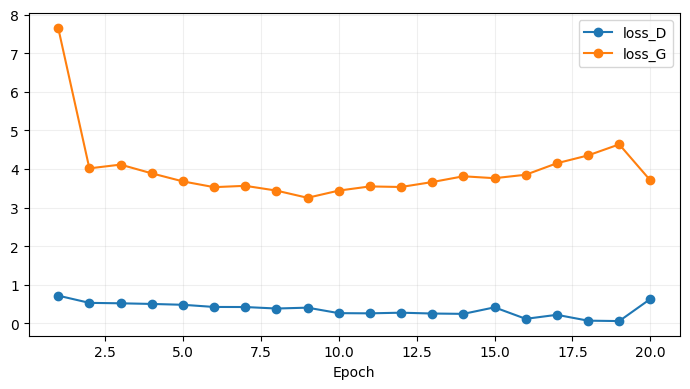

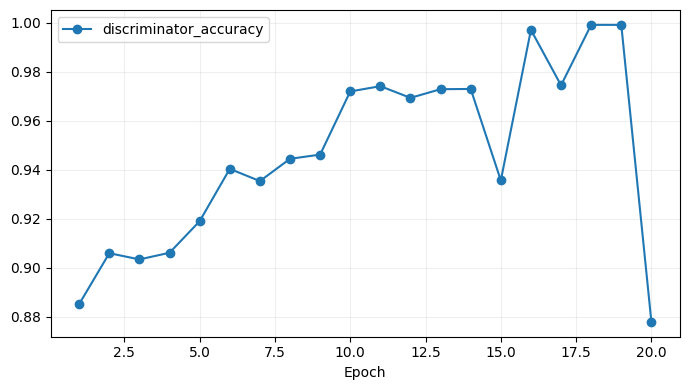

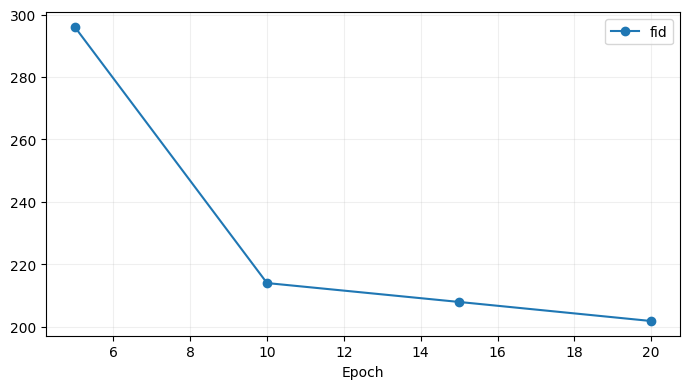

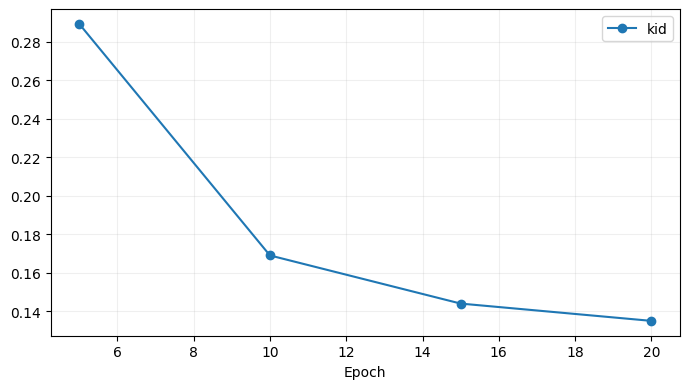

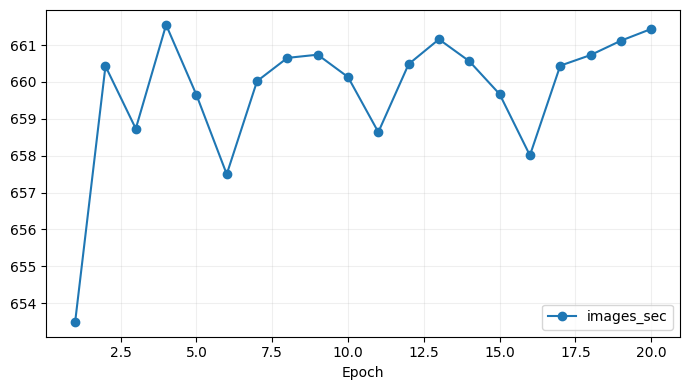

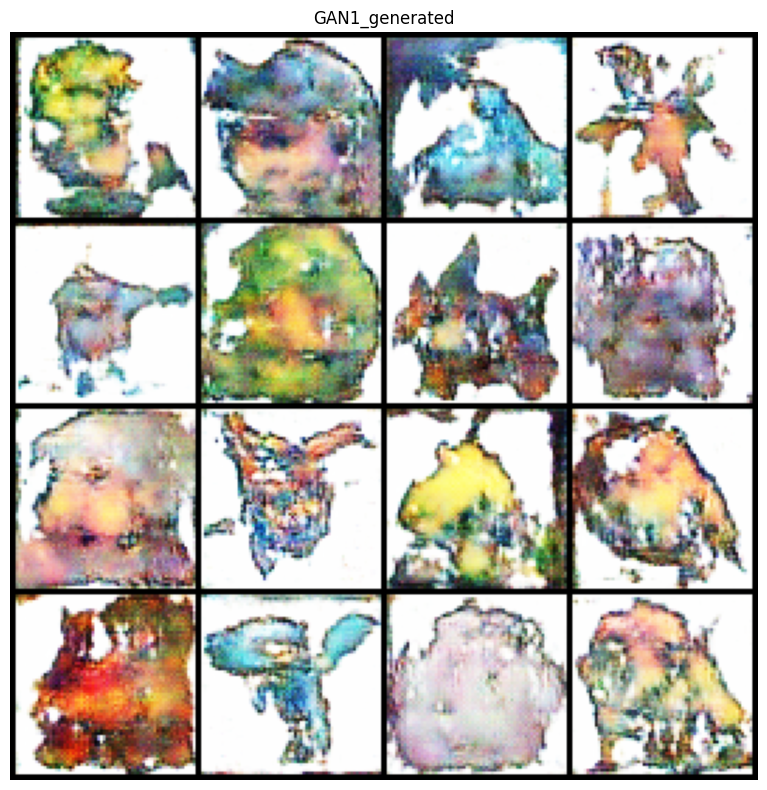

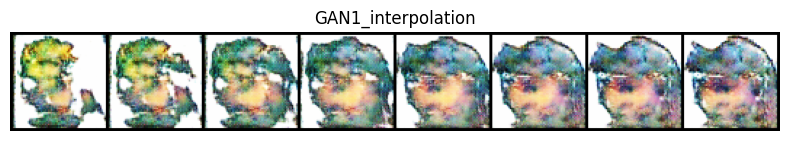

Training {'name': 'GAN2', 'latent_dim': 100, 'lr_G': 0.0002, 'lr_D': 0.0001}
#1: loss_D 0.891, loss_G 5.759
#2: loss_D 0.111, loss_G 7.101
#3: loss_D 0.213, loss_G 5.991
#4: loss_D 0.434, loss_G 4.061
#5: loss_D 0.525, loss_G 3.632
#6: loss_D 0.518, loss_G 3.476
#7: loss_D 0.463, loss_G 3.601
#8: loss_D 0.524, loss_G 3.331
#9: loss_D 0.548, loss_G 3.074
#10: loss_D 0.519, loss_G 2.785
#11: loss_D 0.541, loss_G 2.702
#12: loss_D 0.510, loss_G 2.610
#13: loss_D 0.394, loss_G 2.607
#14: loss_D 0.382, loss_G 2.783
#15: loss_D 0.345, loss_G 2.771
#16: loss_D 0.357, loss_G 2.890
#17: loss_D 0.241, loss_G 2.882
#18: loss_D 0.296, loss_G 3.014
#19: loss_D 0.229, loss_G 3.150
#20: loss_D 0.314, loss_G 3.234
loss_D 0.314, loss_G 3.234, 659.1 examples/sec on cuda


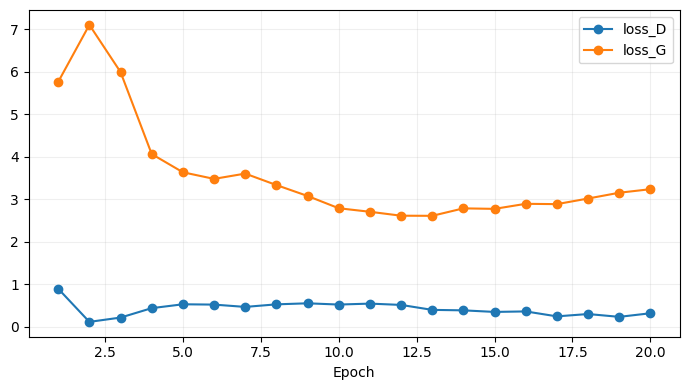

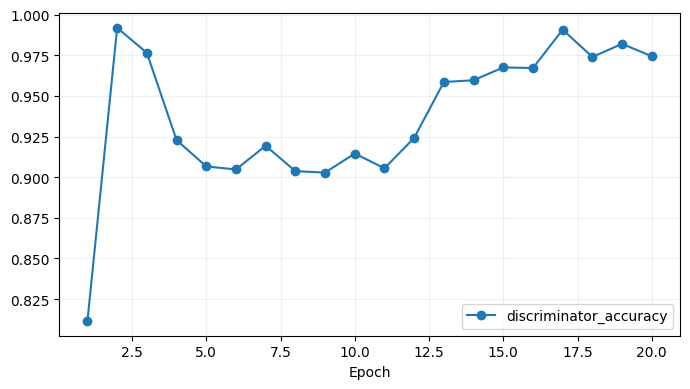

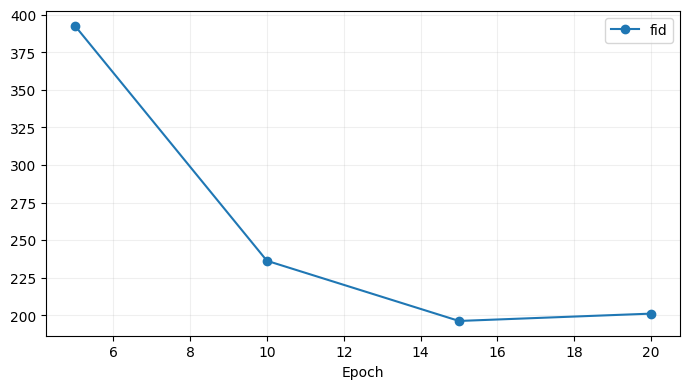

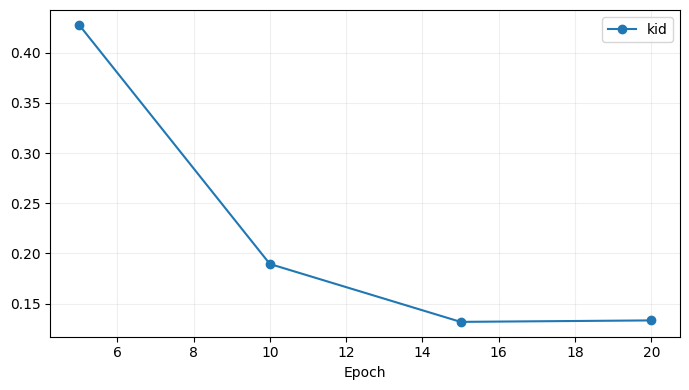

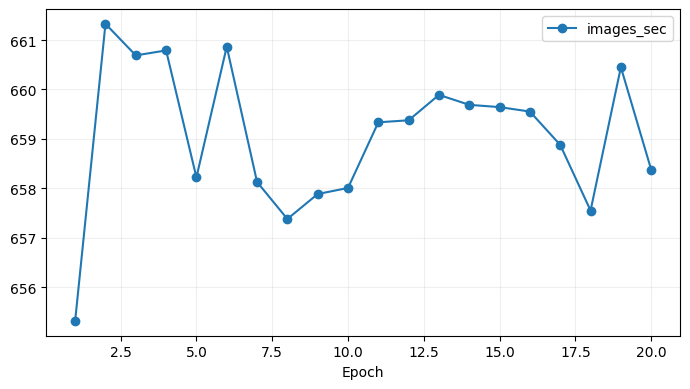

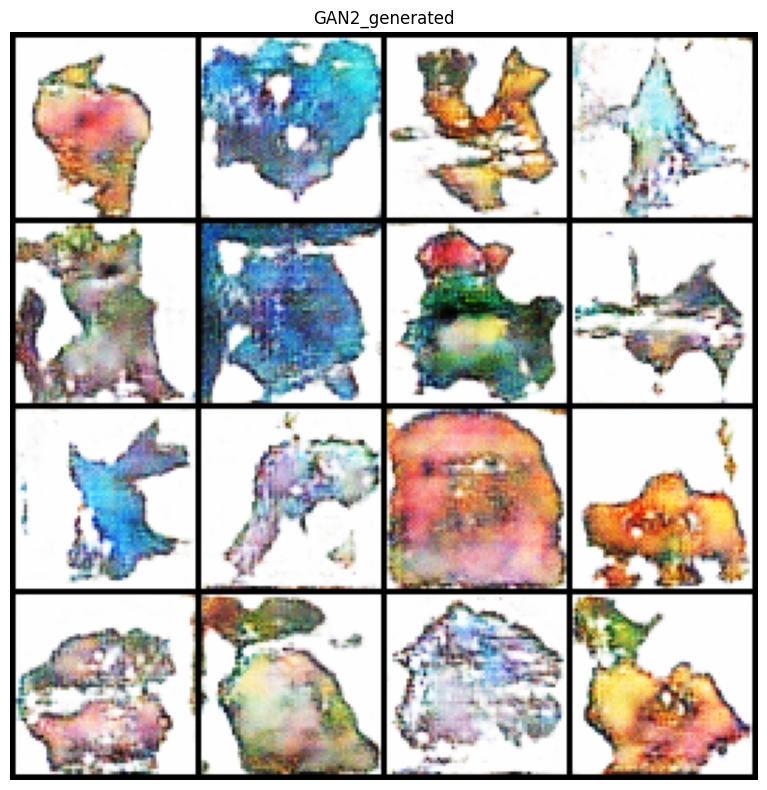

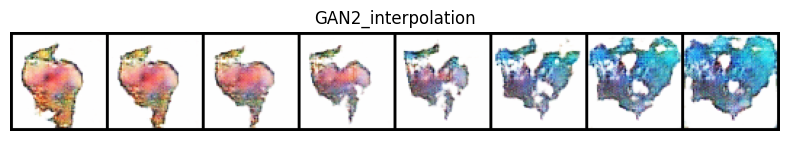

Training {'name': 'GAN3', 'latent_dim': 100, 'lr_G': 0.0002, 'lr_D': 5e-05}
#1: loss_D 4.611, loss_G 1.650
#2: loss_D 1.555, loss_G 1.090
#3: loss_D 1.281, loss_G 1.047
#4: loss_D 1.223, loss_G 0.979
#5: loss_D 1.248, loss_G 0.934
#6: loss_D 1.185, loss_G 1.029
#7: loss_D 1.149, loss_G 1.123
#8: loss_D 1.103, loss_G 1.213
#9: loss_D 1.095, loss_G 1.200
#10: loss_D 1.079, loss_G 1.189
#11: loss_D 1.066, loss_G 1.194
#12: loss_D 1.046, loss_G 1.203
#13: loss_D 1.014, loss_G 1.249
#14: loss_D 1.003, loss_G 1.238
#15: loss_D 0.963, loss_G 1.258
#16: loss_D 0.915, loss_G 1.326
#17: loss_D 0.871, loss_G 1.374
#18: loss_D 0.811, loss_G 1.438
#19: loss_D 0.768, loss_G 1.501
#20: loss_D 0.719, loss_G 1.573
loss_D 0.719, loss_G 1.573, 659.6 examples/sec on cuda


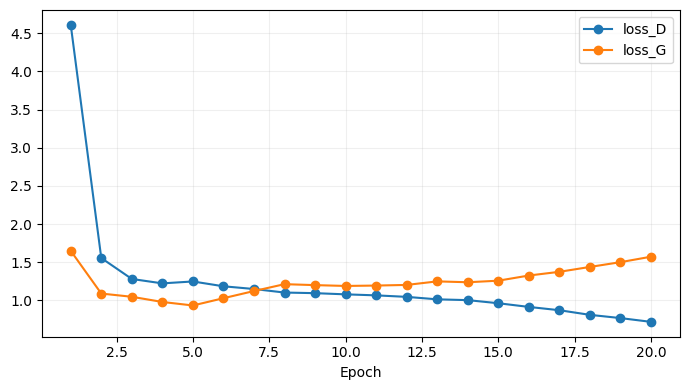

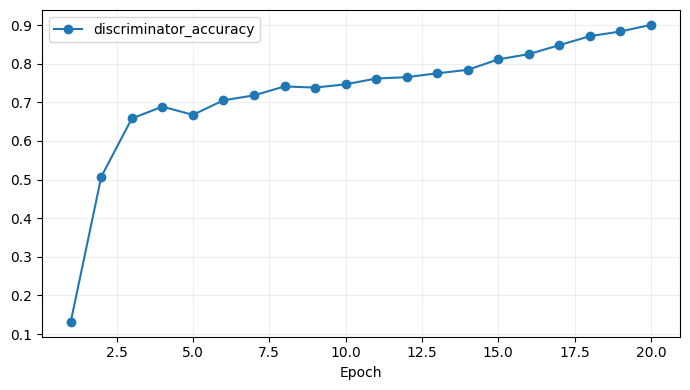

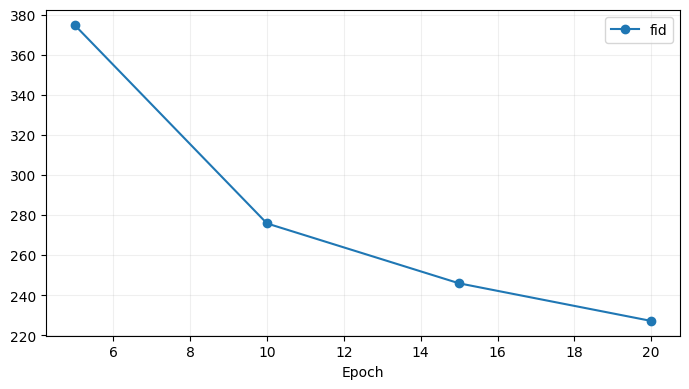

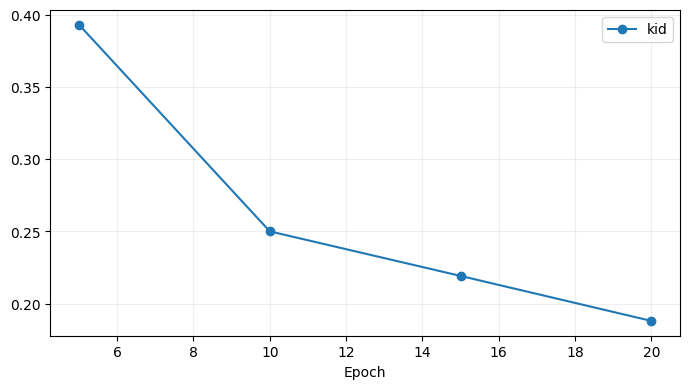

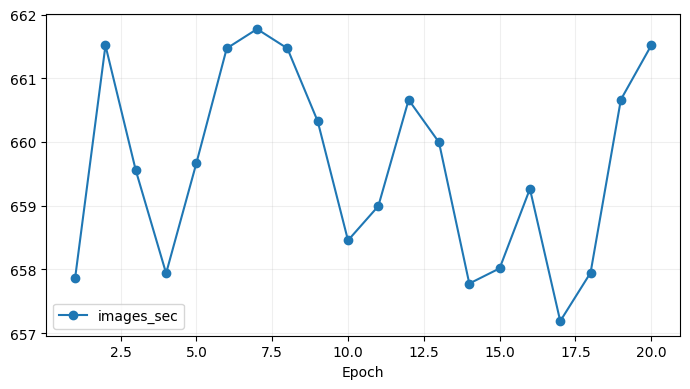

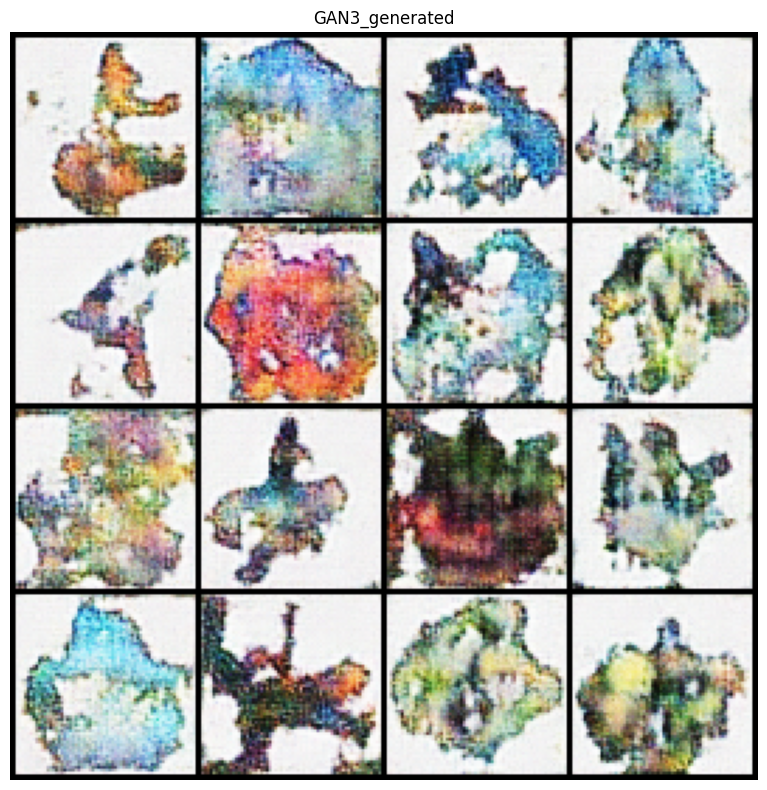

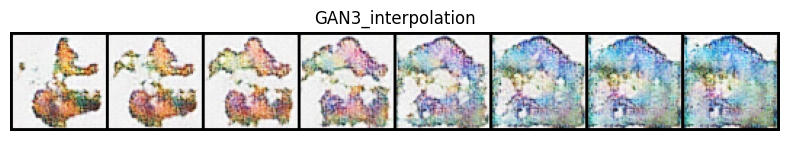

In [15]:
def run_gan(cfg):
    reset_seed(); name=cfg['name']; dim=cfg['latent_dim']
    G,D=build_G(dim),build_D()
    h=train(D,G,loader(),EPOCHS,cfg['lr_G'],cfg['lr_D'],dim,name)
    plot_history(h,[['loss_D','loss_G'],['discriminator_accuracy'],['fid'],['kid'],['images_sec']],name)
    G.eval()
    with torch.no_grad():
        z=torch.randn(16,dim,1,1,device=device,generator=torch.Generator(device=device).manual_seed(SEED))
        grid_save(G(z)*.5+.5,name+'_generated')
        a=torch.linspace(0,1,8,device=device).view(-1,1,1,1)
        grid_save(G((1-a)*z[0]+a*z[1])*.5+.5,name+'_interpolation',nrow=8)
    return h

gan_histories={}
for cfg in GAN_CONFIGS:
    print('Training',cfg)
    gan_histories[cfg['name']]=run_gan(cfg)
    gc.collect(); torch.cuda.empty_cache()


## 3. Comparison of all experiments
The table uses final-epoch metrics for a common training budget. FID is a selection criterion, not proof of visual quality. The held-out folders are used for validation and model selection, not an independent test set.

,model,name,latent_dim,lr,epochs,batch_size,FID,KID,KID_std,training_seconds,images_sec,MSE,PSNR,SSIM,best_val_epoch,lr_G,lr_D,D_accuracy
0,VAE,VAE1,128,0.0010,20,128,292.477570,0.266193,0.016335,271.442669,2392.328377,0.033894,14.961340,0.419932,3.0,NaN,NaN,NaN
1,VAE,VAE2,64,0.0010,20,128,293.763550,0.268753,0.008080,271.183545,2394.614319,0.034954,14.833141,0.412912,4.0,NaN,NaN,NaN
2,VAE,VAE3,128,0.0005,20,128,290.442749,0.257875,0.016952,270.560537,2400.128290,0.030498,15.424252,0.451201,5.0,NaN,NaN,NaN
3,GAN,GAN1,100,NaN,20,128,201.831635,0.135023,0.005384,984.279787,659.751433,NaN,NaN,NaN,NaN,0.0002,0.00020,0.877807
4,GAN,GAN2,100,NaN,20,128,201.068680,0.133211,0.005475,985.305063,659.064918,NaN,NaN,NaN,NaN,0.0002,0.00010,0.974360
5,GAN,GAN3,100,NaN,20,128,227.194626,0.188079,0.005651,984.507581,659.598781,NaN,NaN,NaN,NaN,0.0002,0.00005,0.900551


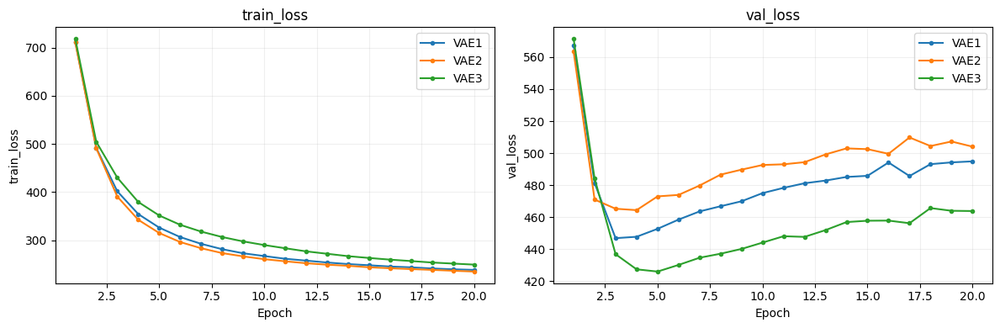

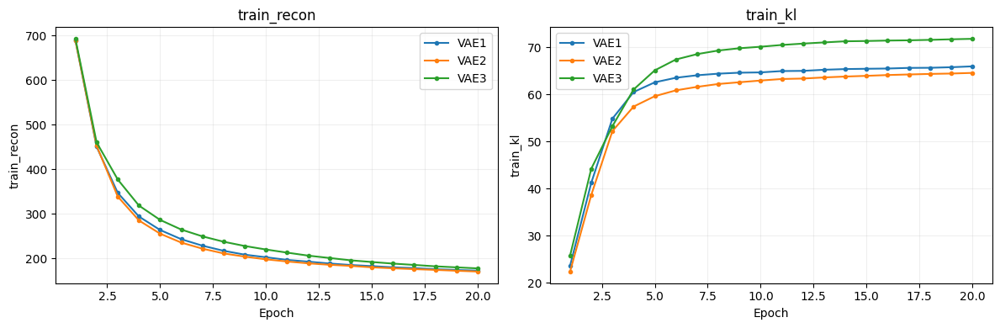

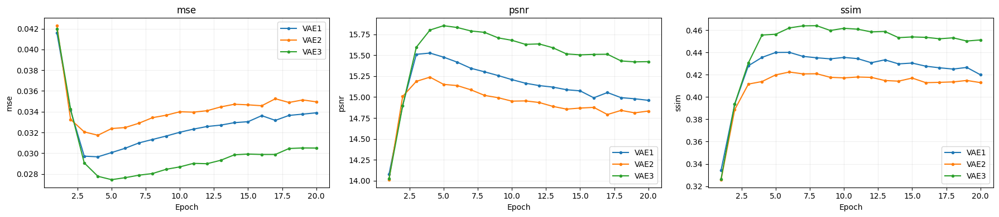

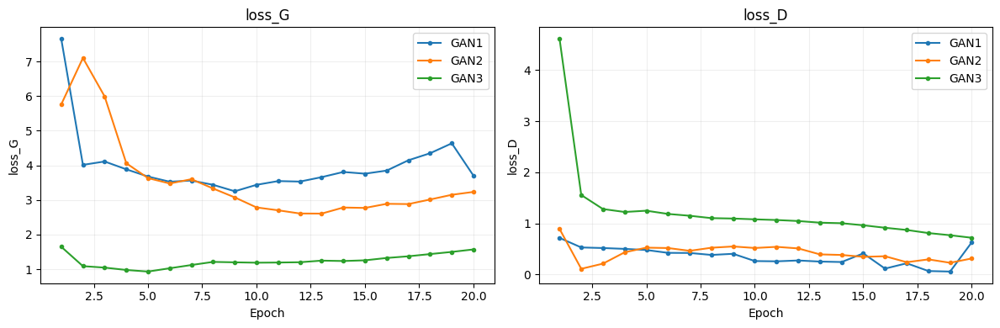

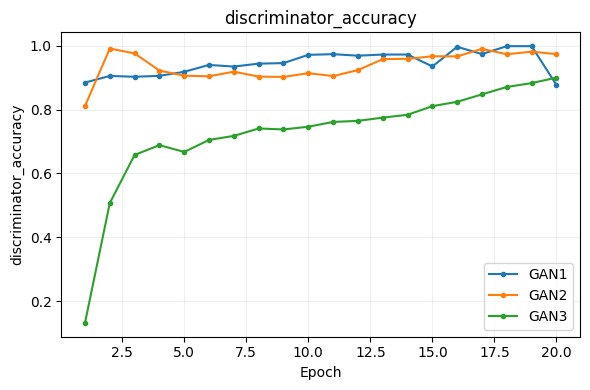

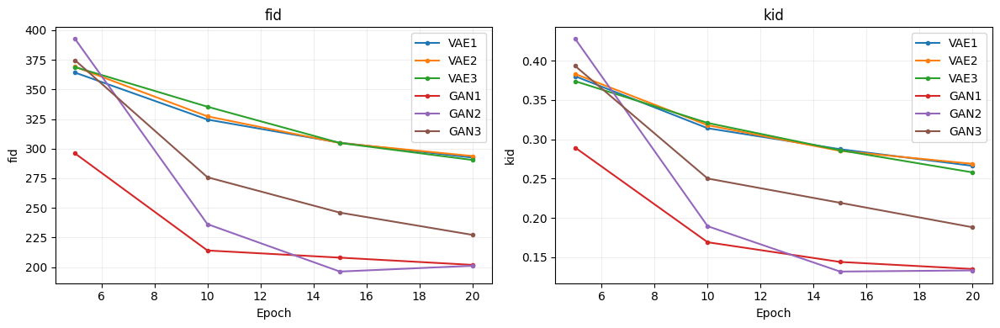

In [16]:
rows=[]
for kind, configs, histories in [('VAE',VAE_CONFIGS,vae_histories),('GAN',GAN_CONFIGS,gan_histories)]:
    for cfg in configs:
        h=histories[cfg['name']]; last=h.iloc[-1]
        row=dict(model=kind,**cfg,epochs=len(h),batch_size=batch_size,
                 FID=last.fid,KID=last.kid,KID_std=last.kid_std,
                 training_seconds=h.train_seconds.sum(),
                 images_sec=len(train_idx)*len(h)/h.train_seconds.sum())
        if kind=='VAE':
            row.update(MSE=last.mse,PSNR=last.psnr,SSIM=last.ssim,
                       best_val_epoch=int(h.loc[h.val_loss.idxmin(),'epoch']))
        else: row['D_accuracy']=last.discriminator_accuracy
        rows.append(row)
summary=pd.DataFrame(rows)
summary.to_csv(OUT/'summary.csv',index=False)
display(summary)

def compare(histories, cols, name):
    fig,axes=plt.subplots(1,len(cols),figsize=(6*len(cols),4),squeeze=False)
    for ax,col in zip(axes[0],cols):
        for label,h in histories.items():
            d=h.dropna(subset=[col]); ax.plot(d.epoch,d[col],marker='o',ms=3,label=label)
        ax.set(xlabel='Epoch',ylabel=col,title=col); ax.legend(); ax.grid(alpha=.2)
    fig.tight_layout(); fig.savefig(OUT/(name+'.png'),dpi=150); plt.show(); plt.close(fig)
compare(vae_histories,['train_loss','val_loss'],'VAE_loss_comparison')
compare(vae_histories,['train_recon','train_kl'],'VAE_loss_components')
compare(vae_histories,['mse','psnr','ssim'],'VAE_reconstruction_metrics')
compare(gan_histories,['loss_G','loss_D'],'GAN_loss_comparison')
compare(gan_histories,['discriminator_accuracy'],'GAN_accuracy_comparison')
compare({**vae_histories,**gan_histories},['fid','kid'],'generation_metrics_comparison')


## 4. Best results for the report

,model,name,latent_dim,lr,epochs,batch_size,FID,KID,KID_std,training_seconds,images_sec,MSE,PSNR,SSIM,best_val_epoch,lr_G,lr_D,D_accuracy
4,GAN,GAN2,100,NaN,20,128,201.068680,0.133211,0.005475,985.305063,659.064918,NaN,NaN,NaN,NaN,0.0002,0.0001,0.97436
2,VAE,VAE3,128,0.0005,20,128,290.442749,0.257875,0.016952,270.560537,2400.128290,0.030498,15.424252,0.451201,5.0,NaN,NaN,NaN


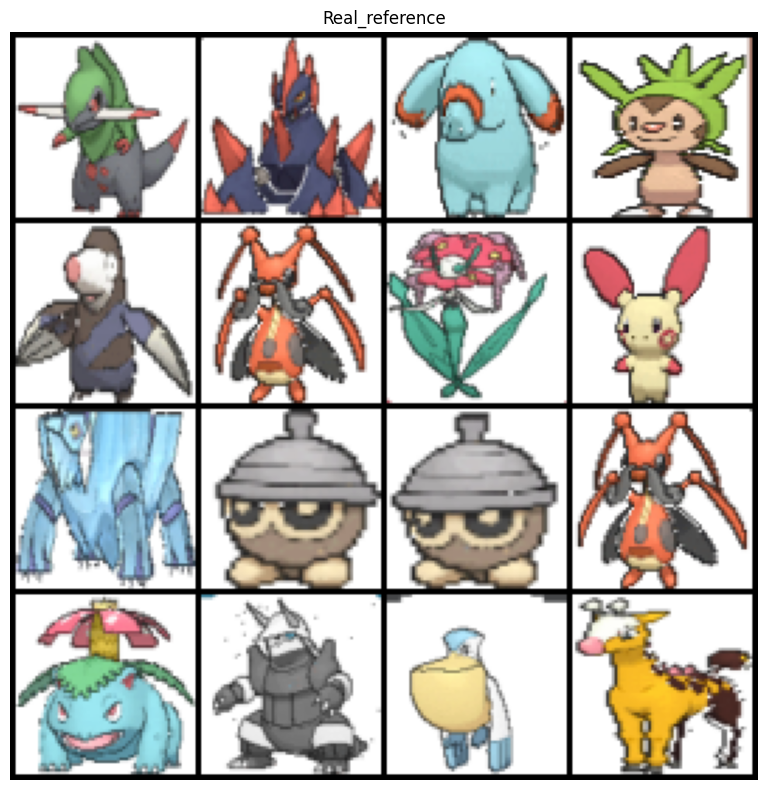

Best configuration: GAN2


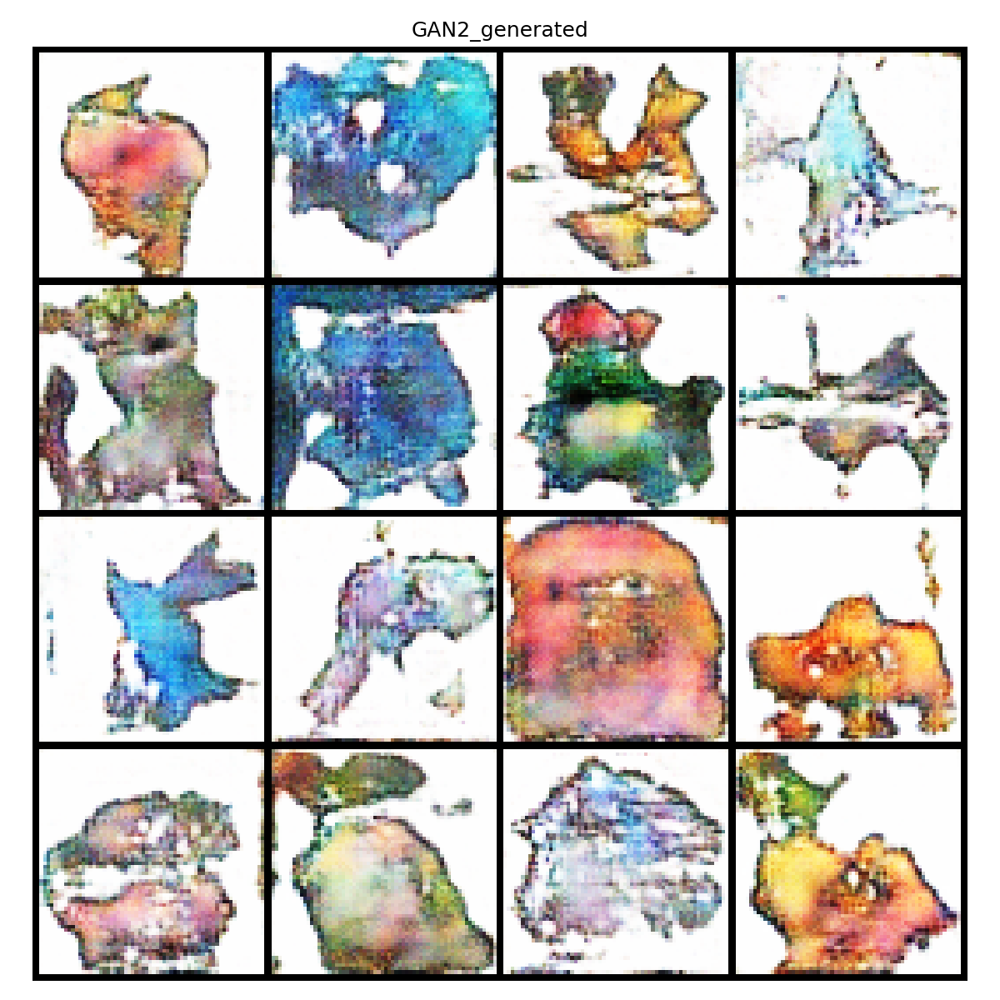

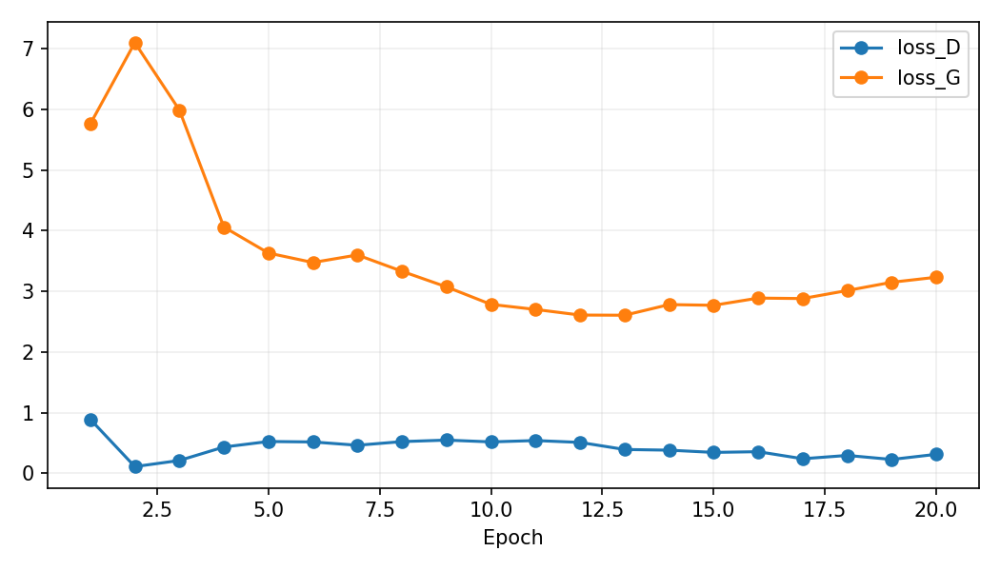

Best configuration: VAE3


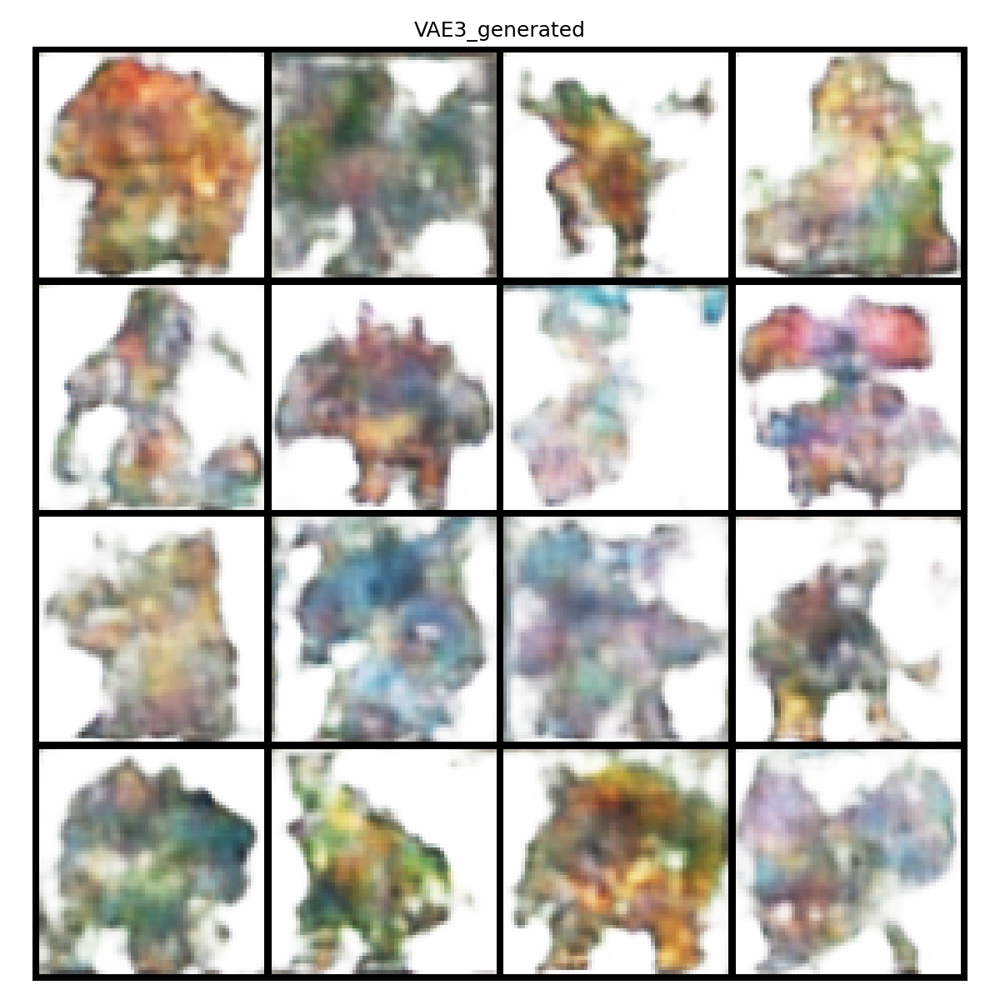

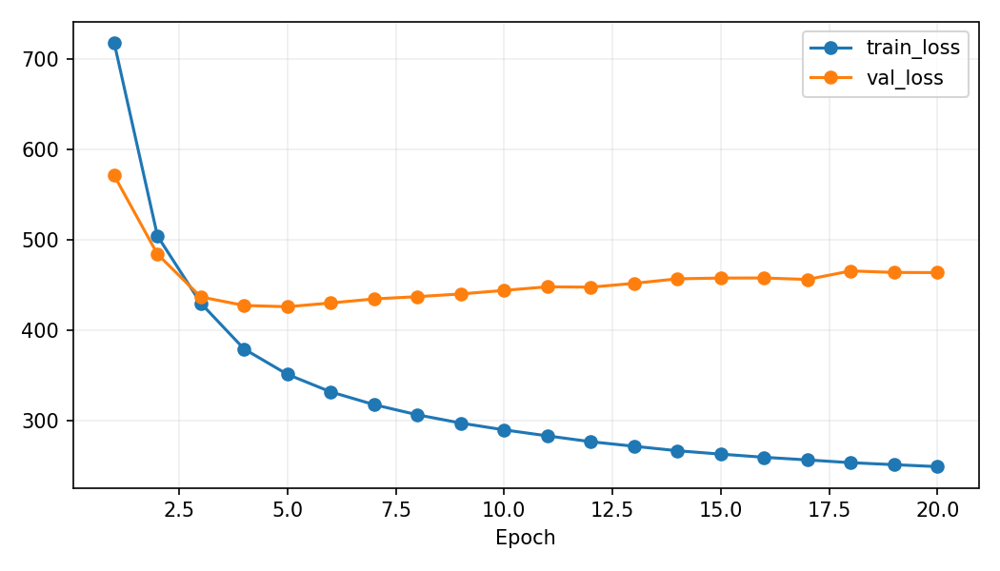

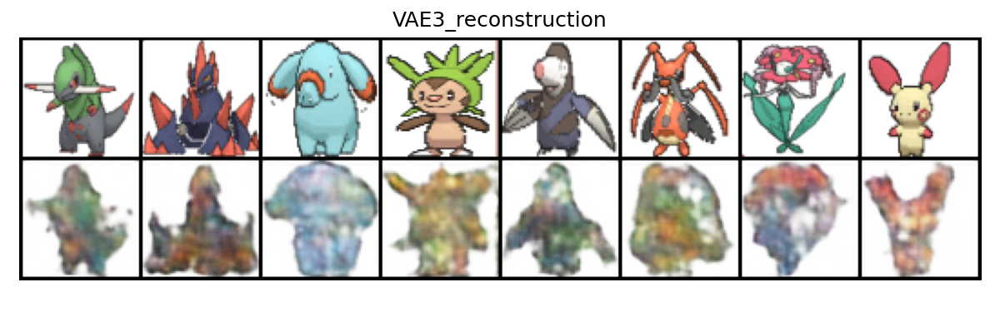

In [17]:
from IPython.display import Image, display
best=summary.loc[summary.groupby('model').FID.idxmin()]
display(best)
best.to_csv(OUT/'best_configurations.csv',index=False)
grid_save(ref_images[:16],'Real_reference')
for _,r in best.iterrows():
    name=r['name']; print('Best configuration:',name)
    files=[name+'_generated.png']
    if r['model']=='VAE': files += [name+'_train_loss.png',name+'_reconstruction.png']
    else: files += [name+'_loss_D.png']
    for file in files: display(Image(filename=str(OUT/file)))


In [18]:
import shutil
archive=shutil.make_archive('pokemon_experiments','zip',root_dir=OUT)
print('Download the results archive from Kaggle Output:',archive)


Download the results archive from Kaggle Output: /kaggle/working/pokemon_experiments.zip
